In [1]:
import numpy as np
import pandas as pd

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [4]:
import os

In [5]:
processed_dir = "../data/processed"

In [6]:
X_train = pd.read_csv(os.path.join(processed_dir, "X_train.csv"))
X_test = pd.read_csv(os.path.join(processed_dir, "X_test.csv"))
y_train = pd.read_csv(os.path.join(processed_dir, "y_train.csv")).squeeze("columns")
y_test = pd.read_csv(os.path.join(processed_dir, "y_test.csv")).squeeze("columns")

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")

X_train shape: (534932, 17)
X_test shape:  (133733, 17)
y_train shape: (534932,)
y_test shape:  (133733,)


In [7]:
X_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 534932 entries, 0 to 534931
Data columns (total 17 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Age                          534932 non-null  int64  
 1   Annual_Income_USD            534932 non-null  float64
 2   Daily_Commute_km             534932 non-null  float64
 3   Number_of_Cars_Owned         534932 non-null  int64  
 4   Charging_Stations_Near_Home  534932 non-null  int64  
 5   Charging_Stations_Near_Work  534932 non-null  int64  
 6   Environmental_Concern_Level  534932 non-null  float64
 7   Gender                       534932 non-null  str    
 8   City_Type                    534932 non-null  str    
 9   Current_Car_Type             534932 non-null  str    
 10  Home_Charging_Possible       534932 non-null  str    
 11  Subsidy_Available            534932 non-null  str    
 12  Range_Anxiety_Level          534932 non-null  str    
 13  Total_Char

In [8]:
y_train.info()

<class 'pandas.Series'>
RangeIndex: 534932 entries, 0 to 534931
Series name: Will_Buy_EV
Non-Null Count   Dtype
--------------   -----
534932 non-null  int64
dtypes: int64(1)
memory usage: 4.1 MB


# ***Encoding***

In [9]:
anxiety_map = {'Low': 0, 'Medium': 1, 'High': 2}

In [10]:
X_train['Home_Charging_Possible'] = X_train['Home_Charging_Possible'].map({'Yes': 1, 'No': 0})
X_test['Home_Charging_Possible'] = X_test['Home_Charging_Possible'].map({'Yes': 1, 'No': 0})

In [11]:
X_train['Range_Anxiety_Level'] = X_train['Range_Anxiety_Level'].map(anxiety_map)
X_test['Range_Anxiety_Level'] = X_test['Range_Anxiety_Level'].map(anxiety_map)

In [12]:
X_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 534932 entries, 0 to 534931
Data columns (total 17 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Age                          534932 non-null  int64  
 1   Annual_Income_USD            534932 non-null  float64
 2   Daily_Commute_km             534932 non-null  float64
 3   Number_of_Cars_Owned         534932 non-null  int64  
 4   Charging_Stations_Near_Home  534932 non-null  int64  
 5   Charging_Stations_Near_Work  534932 non-null  int64  
 6   Environmental_Concern_Level  534932 non-null  float64
 7   Gender                       534932 non-null  str    
 8   City_Type                    534932 non-null  str    
 9   Current_Car_Type             534932 non-null  str    
 10  Home_Charging_Possible       534932 non-null  int64  
 11  Subsidy_Available            534932 non-null  str    
 12  Range_Anxiety_Level          534932 non-null  int64  
 13  Total_Char

In [13]:
for col in ['Gender', 'City_Type', 'Current_Car_Type', 'Subsidy_Available']:
    print(col, X_train[col].unique())

Gender <StringArray>
['Female', 'Male', 'Other']
Length: 3, dtype: str
City_Type <StringArray>
['Suburban', 'Urban', 'Rural']
Length: 3, dtype: str
Current_Car_Type <StringArray>
['SUV', 'Sedan', 'Truck', 'Hatchback']
Length: 4, dtype: str
Subsidy_Available <StringArray>
['Yes', 'No']
Length: 2, dtype: str


In [14]:
X_train['Subsidy_Available'] = X_train['Subsidy_Available'].map({'Yes': 1, 'No': 0})
X_test['Subsidy_Available'] = X_test['Subsidy_Available'].map({'Yes': 1, 'No': 0})

In [16]:
from sklearn.preprocessing import OneHotEncoder

In [17]:
encoder = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')

In [18]:
cols_to_encode = ['Gender', 'City_Type', 'Current_Car_Type']

In [19]:
train_encoded = encoder.fit_transform(X_train[cols_to_encode])
test_encoded = encoder.transform(X_test[cols_to_encode])

encoded_col_names = encoder.get_feature_names_out(cols_to_encode)

train_encoded_df = pd.DataFrame(train_encoded, columns=encoded_col_names, index=X_train.index)
test_encoded_df = pd.DataFrame(test_encoded, columns=encoded_col_names, index=X_test.index)

X_train = pd.concat([X_train.drop(columns=cols_to_encode), train_encoded_df], axis=1)
X_test = pd.concat([X_test.drop(columns=cols_to_encode), test_encoded_df], axis=1)

In [20]:
X_train.isna().sum()

Age                            0
Annual_Income_USD              0
Daily_Commute_km               0
Number_of_Cars_Owned           0
Charging_Stations_Near_Home    0
Charging_Stations_Near_Work    0
Environmental_Concern_Level    0
Home_Charging_Possible         0
Subsidy_Available              0
Range_Anxiety_Level            0
Total_Charging_Stations        0
Has_Any_Charging_Access        0
Commute_Anxiety_Interaction    0
Income_Per_Car                 0
Gender_Male                    0
Gender_Other                   0
City_Type_Suburban             0
City_Type_Urban                0
Current_Car_Type_SUV           0
Current_Car_Type_Sedan         0
Current_Car_Type_Truck         0
dtype: int64

In [21]:
X_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 534932 entries, 0 to 534931
Data columns (total 21 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Age                          534932 non-null  int64  
 1   Annual_Income_USD            534932 non-null  float64
 2   Daily_Commute_km             534932 non-null  float64
 3   Number_of_Cars_Owned         534932 non-null  int64  
 4   Charging_Stations_Near_Home  534932 non-null  int64  
 5   Charging_Stations_Near_Work  534932 non-null  int64  
 6   Environmental_Concern_Level  534932 non-null  float64
 7   Home_Charging_Possible       534932 non-null  int64  
 8   Subsidy_Available            534932 non-null  int64  
 9   Range_Anxiety_Level          534932 non-null  int64  
 10  Total_Charging_Stations      534932 non-null  int64  
 11  Has_Any_Charging_Access      534932 non-null  int64  
 12  Commute_Anxiety_Interaction  534932 non-null  float64
 13  Income_Per

## ***`Standard Scaling`***

In [22]:
scaler = StandardScaler()

In [23]:
continuous_cols = [
    'Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned',
    'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work',
    'Environmental_Concern_Level', 'Total_Charging_Stations',
    'Commute_Anxiety_Interaction', 'Income_Per_Car'
]

In [24]:
X_train[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
X_test[continuous_cols] = scaler.transform(X_test[continuous_cols])

In [25]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (534932, 21)
X_test shape: (133733, 21)


In [27]:
import matplotlib.pyplot as plt

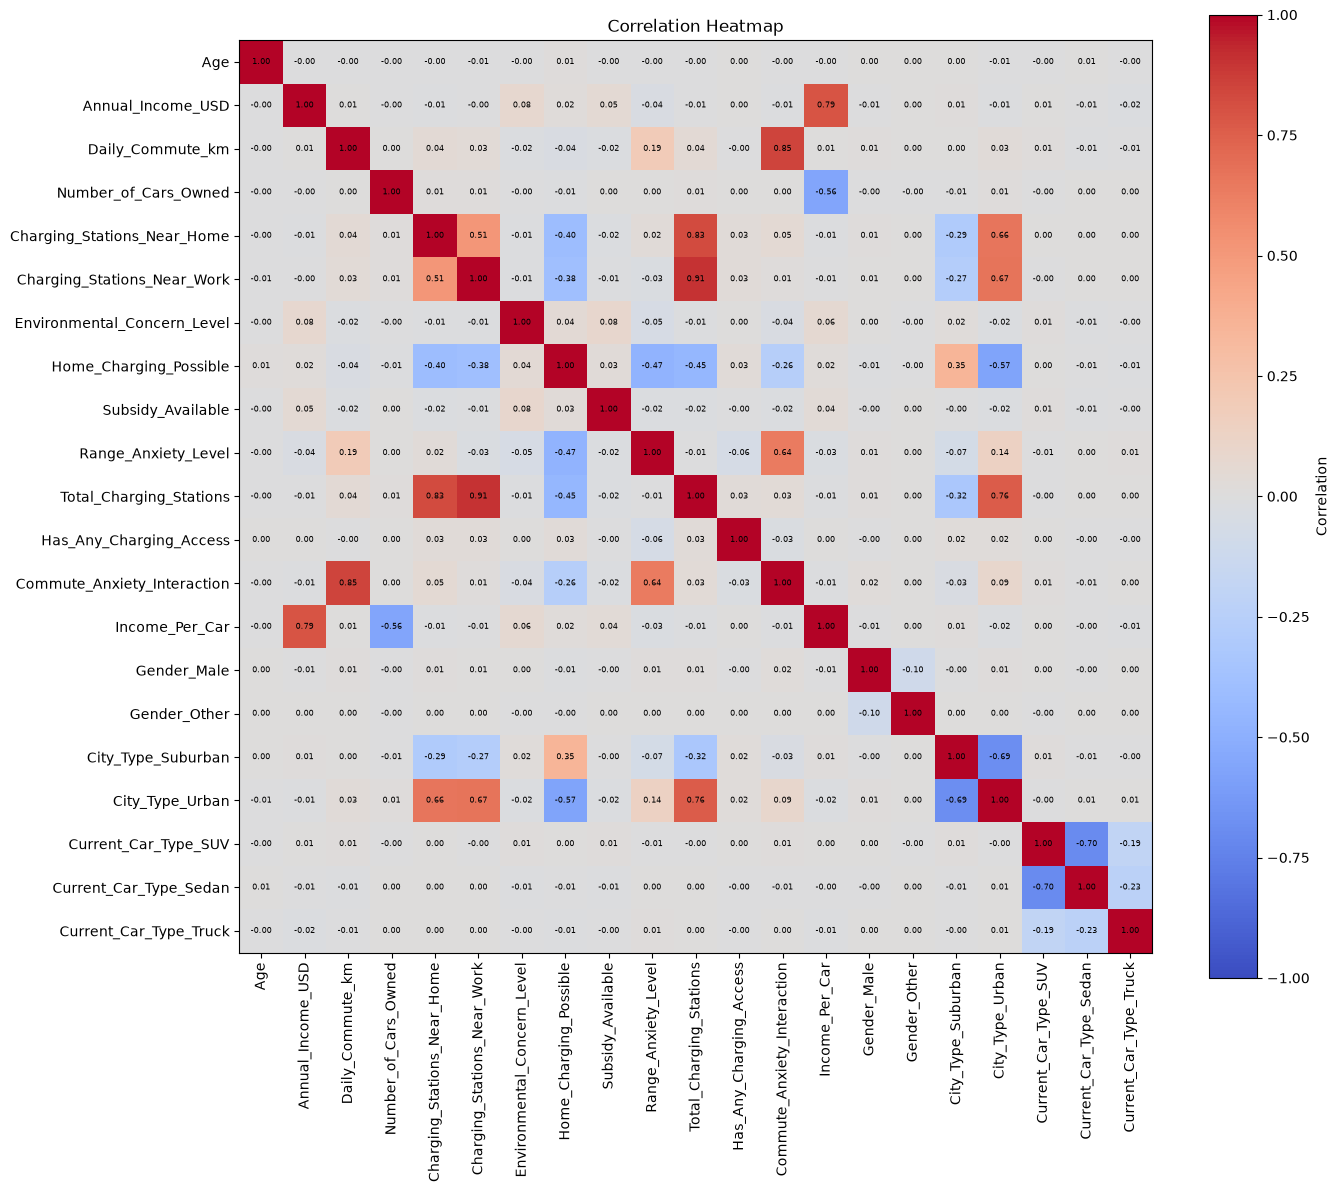

In [28]:
def manual_correlation_matrix(df):
    cols = df.columns
    n = len(cols)
    corr_matrix = np.zeros((n, n))
    
    for i in range(n):
        for j in range(n):
            x = df[cols[i]].values
            y = df[cols[j]].values
            
            mean_x = x.sum() / len(x)
            mean_y = y.sum() / len(y)
            
            cov = ((x - mean_x) * (y - mean_y)).sum()
            std_x = (((x - mean_x) ** 2).sum()) ** 0.5
            std_y = (((y - mean_y) ** 2).sum()) ** 0.5
            
            corr_matrix[i, j] = cov / (std_x * std_y)
    
    return corr_matrix, cols

corr_matrix, cols = manual_correlation_matrix(X_train)

plt.figure(figsize=(14, 12))
plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation')
plt.xticks(range(len(cols)), cols, rotation=90)
plt.yticks(range(len(cols)), cols)

for i in range(len(cols)):
    for j in range(len(cols)):
        plt.text(j, i, f'{corr_matrix[i, j]:.2f}', ha='center', va='center', 
                  color='black', fontsize=6)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [29]:
X_train.drop(columns=['Total_Charging_Stations', 'Income_Per_Car'], inplace=True)
X_test.drop(columns=['Total_Charging_Stations', 'Income_Per_Car'], inplace=True)

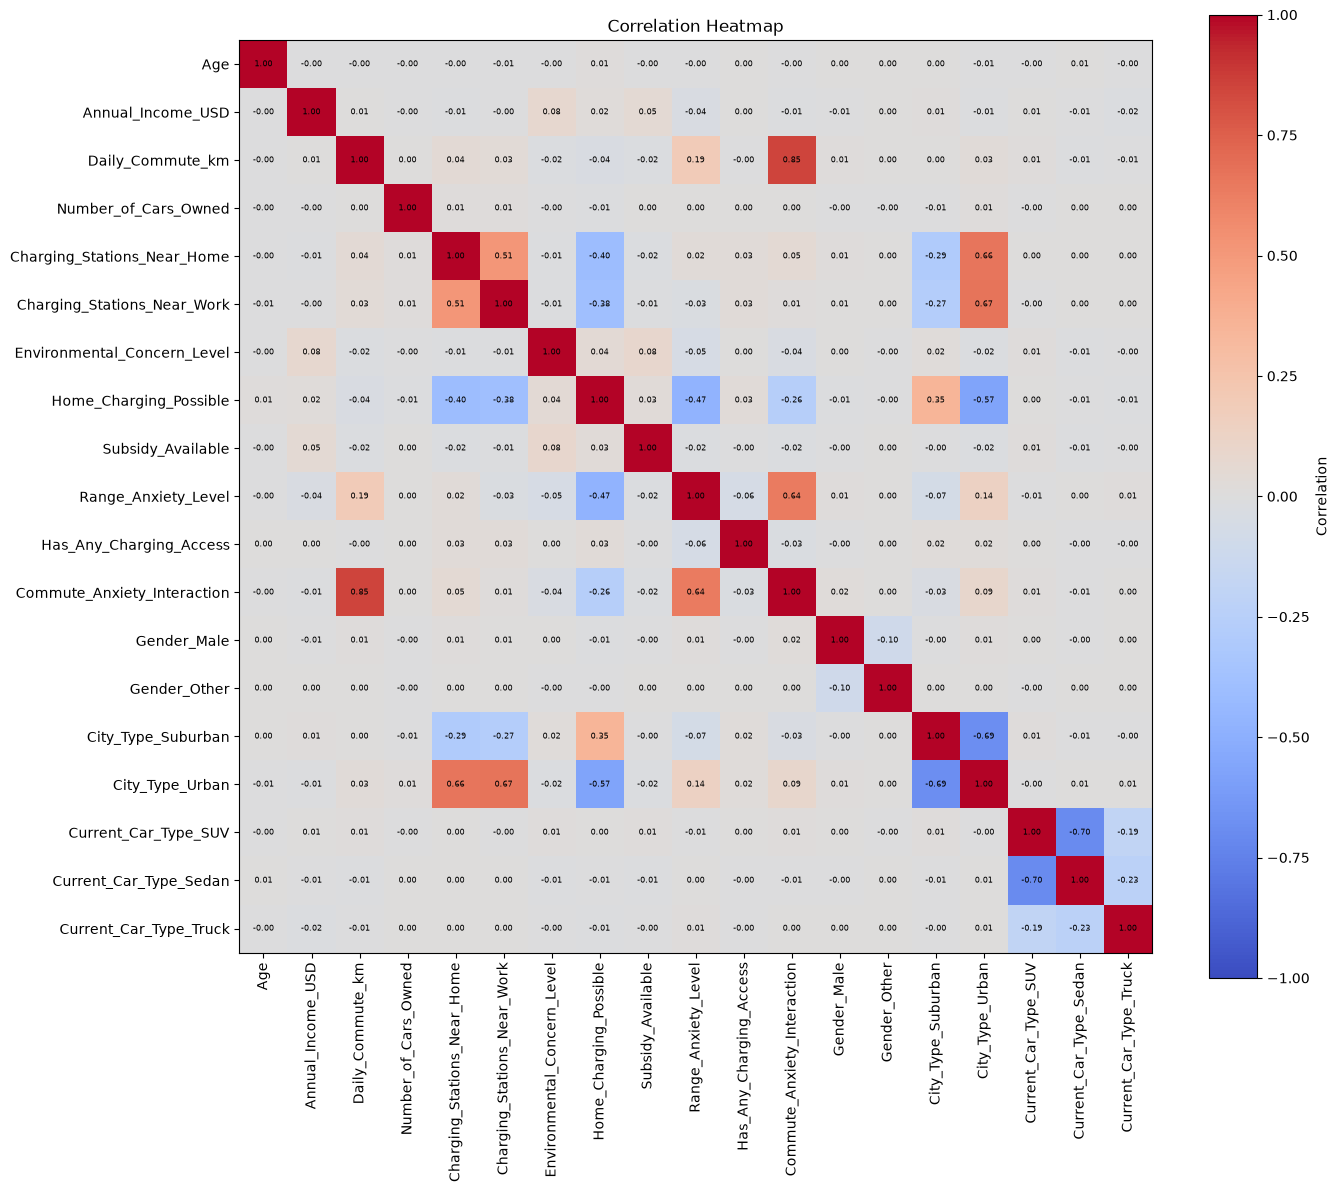

In [30]:
corr_matrix, cols = manual_correlation_matrix(X_train)

plt.figure(figsize=(14, 12))
plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation')
plt.xticks(range(len(cols)), cols, rotation=90)
plt.yticks(range(len(cols)), cols)

for i in range(len(cols)):
    for j in range(len(cols)):
        plt.text(j, i, f'{corr_matrix[i, j]:.2f}', ha='center', va='center', 
                  color='black', fontsize=6)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

## **`Save Data`**

In [31]:
import os

In [32]:
processed_dir = "../data/processed"
os.makedirs(processed_dir, exist_ok=True)

In [33]:
X_train.to_csv(os.path.join(processed_dir, "X_train_new.csv"), index=False)
X_test.to_csv(os.path.join(processed_dir, "X_test_new.csv"), index=False)
y_train.to_csv(os.path.join(processed_dir, "y_train_new.csv"), index=False)
y_test.to_csv(os.path.join(processed_dir, "y_test_new.csv"), index=False)
print("data/processed!")

data/processed!
